# FP32 Baseline: CIFAR-10 Image Classification
**Project:** Evaluating Neural Network Quantization for Efficient Deep Learning Inference

**Goal:** To establish a reproducible floating-point (FP32) baseline for a pretrained ResNet-18 model on CIFAR-10 before applying INT8 post-training quantization (PTQ).

**Measurements:** Test accuracy, serialized model size, and CPU inference latency.

**Dataset:** CIFAR-10

**Model:** Pretrained ResNet-18 fine-tuned for CIFAR-10

**Initial evaluation size:** 1000 test images


# Configuring the Colab notebook

In [1]:
import platform
import torch
import torchvision

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0)) # Using T4 GPU if possible
else:
    print("Using CPU")

Python: 3.13.15
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


# Installing the module-loading library

In [2]:
%pip install -q timm # Loading pretrained image-classification model from Hugging Face

import copy
import os
import random
import time
import json
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import timm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Setup complete.")

Setup complete.


# Loading the pre-trained ResNet-18 model

In [3]:
MODEL_ID = "hf_hub:SamAdamDay/resnet18_cifar10"

model = timm.create_model(
    MODEL_ID,
    pretrained=True
)

model.eval()

print("Model loaded successfully.")
print("Architecture:", model.__class__.__name__)
print("Number of parameters:",
      sum(p.numel() for p in model.parameters()))
print("Number of output classes:", model.num_classes) # Should be 10

config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 44.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded successfully.
Architecture: ResNet
Number of parameters: 11181642
Number of output classes: 10


# Loading CIFAR-10 dataset for the ResNet-18 model
Note that running this below cell will take approx. 25 minutes

In [4]:
# Loading CIFAR-10 dataset for the ResNet-18 model
from torch.utils.data import DataLoader, Subset

DATA_DIR = "./data"
BATCH_SIZE = 32
EVAL_SIZE = 1000

# Using the preprocessing specified by the model card
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.49139968, 0.48215827, 0.44653124),
        std=(0.24703233, 0.24348505, 0.26158768)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

# Fixed and reproducible subset of the official test split
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(
    len(test_dataset), generator=generator
)[:EVAL_SIZE].tolist()

test_subset = Subset(test_dataset, indices)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training images available:", len(train_dataset))
print("Official test images:", len(test_dataset))
print("Images in this evaluation:", len(test_subset))


100%|██████████| 170M/170M [20:26<00:00, 139kB/s]


Training images available: 50000
Official test images: 10000
Images in this evaluation: 1000


# Testing some images to check if everything is working properly

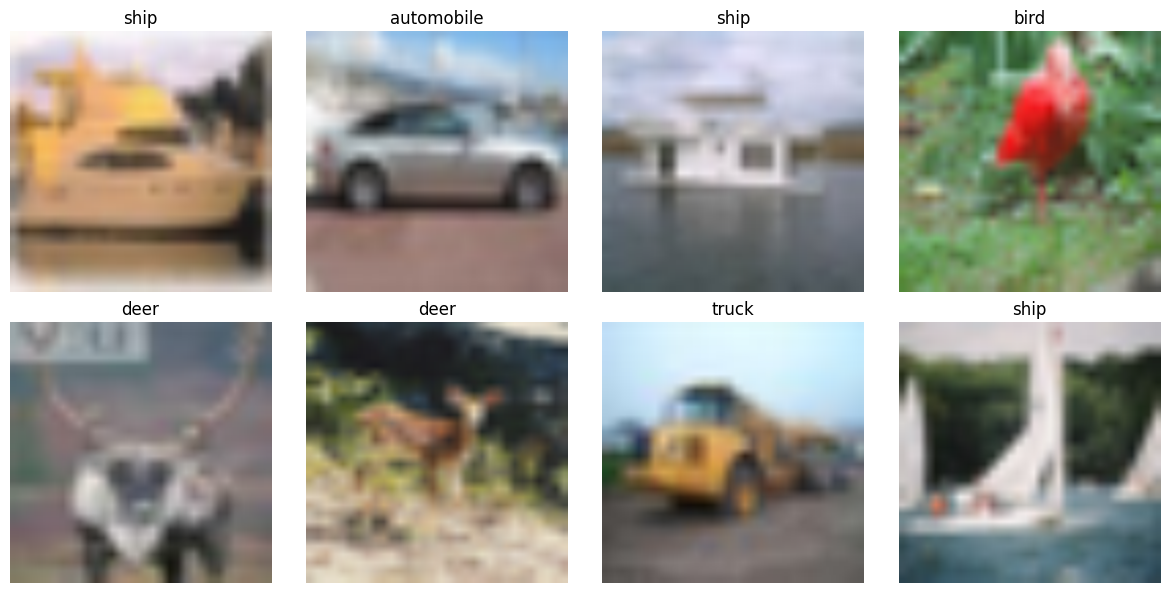

In [6]:
classes = train_dataset.classes

images, labels = next(iter(test_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = torch.tensor(
    (0.49139968, 0.48215827, 0.44653124)
).view(3, 1, 1)

std = torch.tensor(
    (0.24703233, 0.24348505, 0.26158768)
).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image = images[i] * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Measuring the FP32 baseline accuracy

In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

correct = 0
total = 0

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

baseline_accuracy = 100.0 * correct / total

print(f"Device: {device}")
print(f"Correct predictions: {correct}/{total}")
print(f"FP32 test accuracy: {baseline_accuracy:.2f}%")

Device: cuda
Correct predictions: 924/1000
FP32 test accuracy: 92.40%


# Measuring model's file size

In [9]:
os.makedirs("results", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

torch.save(model.cpu().state_dict(), "fp32_state_dict.pt")

fp32_size_mb = os.path.getsize(
    "fp32_state_dict.pt"
) / (1024 ** 2)

print(f"FP32 state-dict size: {fp32_size_mb:.2f} MiB")

model = model.to(device)

FP32 state-dict size: 42.73 MiB


# Measuring CPU inference latency time

In [10]:
# Making a CPU copy for the baseline benchmark
cpu_model = copy.deepcopy(model).cpu().eval()

benchmark_size = 256
benchmark_dataset = Subset(
    test_dataset, indices[:benchmark_size]
)

benchmark_loader = DataLoader(
    benchmark_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Warm-up
with torch.inference_mode():
    for images, _ in list(benchmark_loader)[:3]:
        _ = cpu_model(images)

# Repeat the measurement
timings = []

for _ in range(3):
    start = time.perf_counter()

    with torch.inference_mode():
        for images, _ in benchmark_loader:
            _ = cpu_model(images)

    elapsed = time.perf_counter() - start
    timings.append(elapsed)

median_total_seconds = statistics.median(timings)
fp32_latency_ms = (
    median_total_seconds / benchmark_size
) * 1000

print(f"Median run time: {median_total_seconds:.3f} s")
print(f"FP32 CPU latency: {fp32_latency_ms:.3f} ms/image")

Median run time: 23.932 s
FP32 CPU latency: 93.484 ms/image


# Saving the baseline results as a JSON file

In [18]:
baseline_results = {
    "model": MODEL_ID,
    "dataset": "CIFAR-10",
    "seed": SEED,
    "evaluation_images": total,
    "accuracy_percent": baseline_accuracy,
    "serialized_size_mib": fp32_size_mb,
    "cpu_latency_ms_per_image": fp32_latency_ms,
    "benchmark_images": benchmark_size,
    "batch_size": BATCH_SIZE,
    "device_for_accuracy": str(device),
    "device_for_latency": "CPU",
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
}

with open("results/fp32_baseline.json", "w") as f:
    json.dump(baseline_results, f, indent=2)

pd.DataFrame([baseline_results])

,model,dataset,seed,evaluation_images,accuracy_percent,serialized_size_mib,cpu_latency_ms_per_image,benchmark_images,batch_size,device_for_accuracy,device_for_latency,pytorch_version,torchvision_version
0,hf_hub:SamAdamDay/resnet18_cifar10,CIFAR-10,42,1000,92.4,42.730418,93.484413,256,32,cuda,CPU,2.11.0+cu130,0.26.0+cu130


# Exporting the result table to a JSON file and downloading it


In [19]:
df = pd.DataFrame([baseline_results])
df.to_json('fp32_baseline.json', orient='records', indent=4)
from google.colab import files
files.download('fp32_baseline.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>